## 🏠 Egypt House Prices Analysis
### Dataset Description:
#### This dataset contains real estate property listings in Egypt, including information about property location, type, property area (sqm), number of bedrooms and bathrooms, finishing level, payment method, and year of construction.
#### The dataset also includes property prices, allowing us to analyze property prices and the factors that may affect them across different locations and property types.

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Load Data

In [2]:
df=pd.read_excel('egypt_house_prices.xlsx')
df.head()

,property id,Governorate Name,city region,Property Type,Area sqm,Bedrooms Num,Bathrooms Num,finishing type,payment method,year built,Price EGP
0,EGY-10000,Giza,Dokki,Apartment,140.0,1.0,1,Finished,Cash,2000,4.457784e+06
1,EGY-10001,Gharbia,El Mahalla,Duplex,187.0,3.0,3,Ultra Super Lux,Cash,2019,2.542322e+06
2,EGY-10002,Alexandria,Mami,Apartment,142.0,4.0,4,Semi-Finished,Cash,2002,3.283997e+06
3,EGY-10003,Giza,Faisal,Studio,51.0,3.0,1,Ultra Super Lux,Cash,2012,1.366362e+06
4,EGY-10004,Cairo,Zamalek,Apartment,NaN,NaN,3,Ultra Super Lux,Cash,2006,1.545022e+06


#### Review Data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5120 entries, 0 to 5119
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   property id        5120 non-null   str    
 1   Governorate Name   5120 non-null   str    
 2   city region        5120 non-null   str    
 3   Property Type      5120 non-null   str    
 4   Area sqm           4854 non-null   float64
 5   Bedrooms Num       4911 non-null   float64
 6   Bathrooms Num      5120 non-null   int64  
 7   finishing type     4822 non-null   str    
 8   payment method     5120 non-null   str    
 9   year built         5120 non-null   int64  
 10  Price EGP          4874 non-null   float64
dtypes: float64(3), int64(2), str(6)
memory usage: 440.1 KB


In [4]:
df.describe()

,Area sqm,Bedrooms Num,Bathrooms Num,year built,Price EGP
count,4854.000000,4911.000000,5120.000000,5120.000000,4.874000e+03
mean,164.961681,2.676644,2.148047,2012.158203,4.305177e+06
std,172.467698,1.036455,1.080089,7.237438,8.125464e+06
min,30.000000,1.000000,1.000000,2000.000000,3.480895e+05
25%,103.000000,2.000000,1.000000,2006.000000,2.137734e+06
50%,131.000000,3.000000,2.000000,2012.000000,3.221564e+06
75%,183.000000,3.000000,3.000000,2018.000000,4.770476e+06
max,6600.000000,6.000000,6.000000,2024.000000,2.231853e+08


In [5]:
df.columns

Index(['property id', 'Governorate Name ', 'city region', 'Property Type',
       'Area sqm', 'Bedrooms Num', 'Bathrooms Num', 'finishing type',
       'payment method', 'year built', 'Price EGP'],
      dtype='str')

In [6]:
df.shape

(5120, 11)

In [7]:
#Display data types
df.dtypes

property id              str
Governorate Name         str
city region              str
Property Type            str
Area sqm             float64
Bedrooms Num         float64
Bathrooms Num          int64
finishing type           str
payment method           str
year built             int64
Price EGP            float64
dtype: object

In [8]:
#Check missig values
df.isnull().sum()

property id            0
Governorate Name       0
city region            0
Property Type          0
Area sqm             266
Bedrooms Num         209
Bathrooms Num          0
finishing type       298
payment method         0
year built             0
Price EGP            246
dtype: int64

In [9]:
#Check duplicates
df.duplicated().sum()

np.int64(86)

## Cleaning Data

### Remove Uneeded Columns

In [10]:
df.drop(columns='property id',inplace=True)

### Rename columns

In [11]:
df.columns=df.columns.str.lower().str.replace(" ","_")
df.columns

Index(['governorate_name_', 'city_region', 'property_type', 'area_sqm',
       'bedrooms_num', 'bathrooms_num', 'finishing_type', 'payment_method',
       'year_built', 'price_egp'],
      dtype='str')

In [12]:
df.rename(columns={'governorate_name_': 'governorate_name'}, inplace=True)

### Drop duplicates

In [13]:
df.duplicated().sum()

np.int64(86)

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df.duplicated().sum()

np.int64(0)

### Handle missing values

In [16]:
df.isnull().sum()

governorate_name      0
city_region           0
property_type         0
area_sqm            266
bedrooms_num        209
bathrooms_num         0
finishing_type      298
payment_method        0
year_built            0
price_egp           245
dtype: int64

In [17]:
#Numerical data
df['area_sqm'] = df['area_sqm'].fillna(df['area_sqm'].median())
df['bedrooms_num'] = df['bedrooms_num'].fillna(df['bedrooms_num'].median())
df['price_egp'] = df['price_egp'].fillna(df['price_egp'].median())

In [18]:
#Categorical data
df['finishing_type'] = df['finishing_type'].fillna('unknown')

In [19]:
df.isnull().sum()

governorate_name    0
city_region         0
property_type       0
area_sqm            0
bedrooms_num        0
bathrooms_num       0
finishing_type      0
payment_method      0
year_built          0
price_egp           0
dtype: int64

### Handle outliers

In [35]:
for col in ['area_sqm','price_egp']:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    LB=Q1-1.5*IQR
    UB=Q3+1.5*IQR
    df[col]=df[col].clip(lower=LB,upper=UB)

### Exploratory Data Analysis (EDA) & Visualization

##### 1-Price Distribution Across Property Listings

In [21]:
df.groupby(['governorate_name'])['price_egp'].count().sort_values(ascending=False)

governorate_name
Cairo         1782
Giza          1232
Alexandria     773
Qalyubia       421
Dakahlia       242
Monufia        205
Gharbia        192
Sharqia        187
Name: price_egp, dtype: int64

<Axes: ylabel='Frequency'>

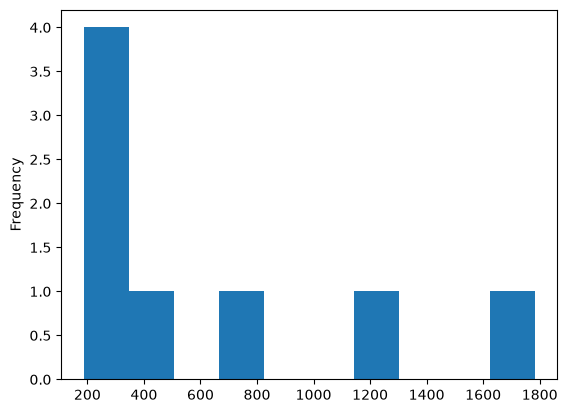

In [22]:
df.groupby(['governorate_name'])['price_egp'].count().plot(kind='hist')

##### 2-Number of Properties by Governorate

<Axes: xlabel='governorate_name'>

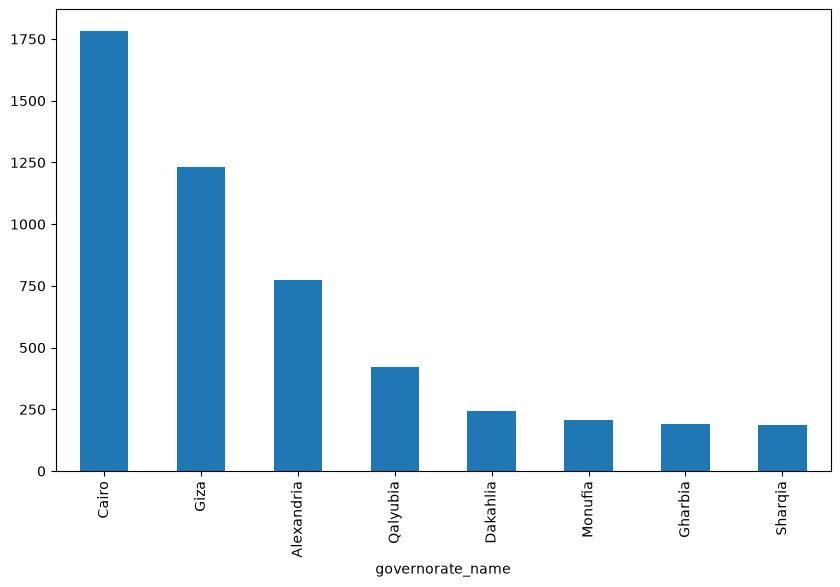

In [23]:
df.groupby(['governorate_name'])['price_egp'].count().sort_values(ascending=False).plot(kind='bar', figsize=(10, 6))

##### 3-Average Price by Governorate

<Axes: ylabel='governorate_name'>

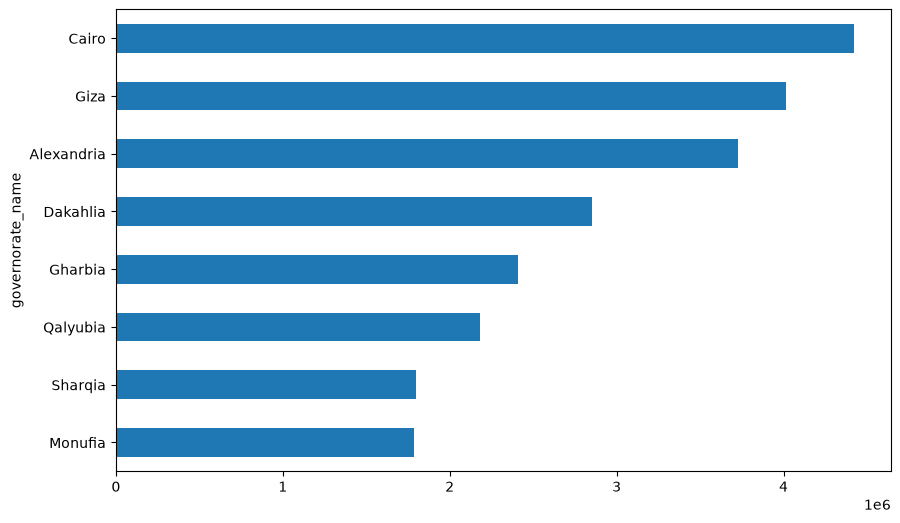

In [24]:
avg_price = df.groupby('governorate_name')['price_egp'].mean().sort_values()

avg_price.plot(kind='barh', figsize=(10, 6))

<Axes: >

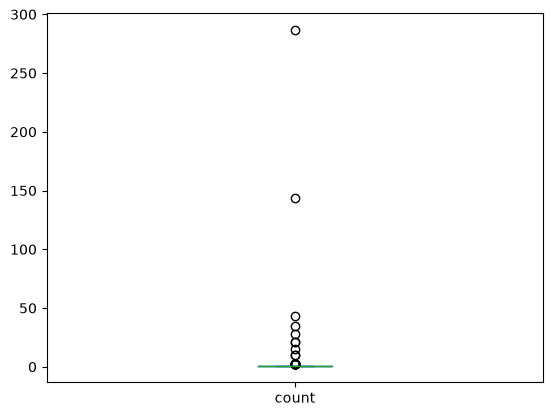

In [25]:
#Showing the relationship between Property (property_type) and (Price)
df.groupby(['property_type'])['price_egp'].value_counts().plot(kind='box')

##### 4-Area vs Price by Property Type

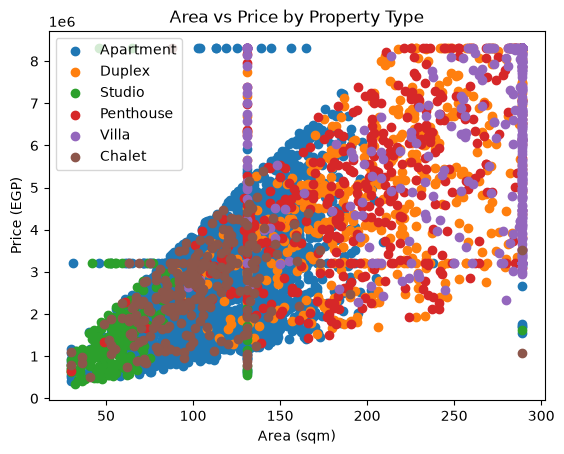

In [26]:
for property_type in df['property_type'].unique():
    data = df[df['property_type'] == property_type]
    
    plt.scatter(
        data['area_sqm'],
        data['price_egp'],
        label=property_type)

plt.xlabel('Area (sqm)')
plt.ylabel('Price (EGP)')
plt.title('Area vs Price by Property Type')
plt.legend()
plt.show()

##### 5-Price by Number of Bedrooms

<Axes: title={'center': 'price_egp'}, xlabel='bedrooms_num'>

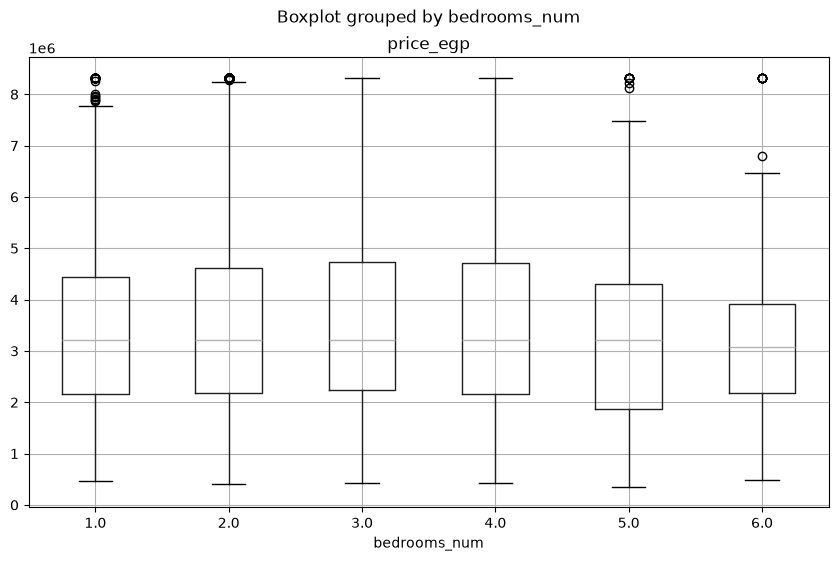

In [27]:
df.boxplot(column='price_egp', by='bedrooms_num', figsize=(10, 6))

##### 6-Price by Finishing Level

<Axes: title={'center': 'price_egp'}, xlabel='finishing_type'>

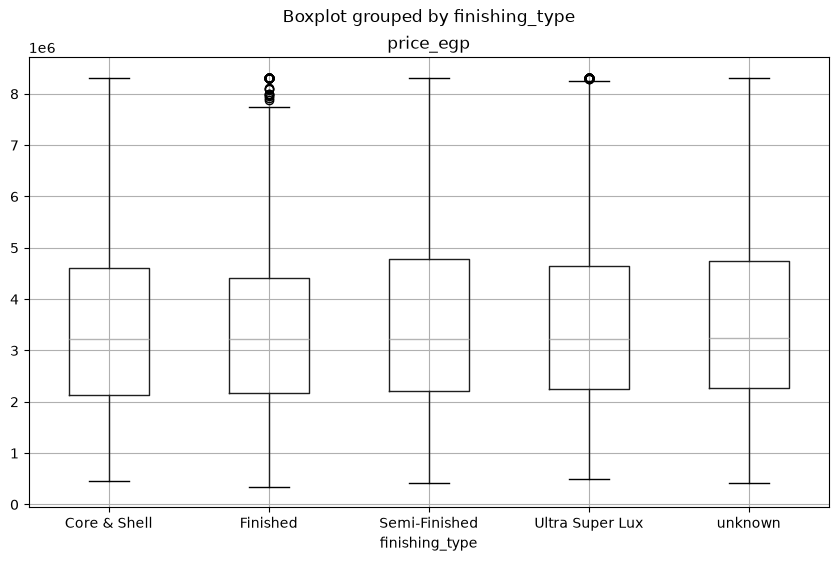

In [28]:
df.boxplot(column='price_egp', by='finishing_type', figsize=(10, 6))

##### 7- Year Built vs Price

<Axes: xlabel='year_built', ylabel='price_egp'>

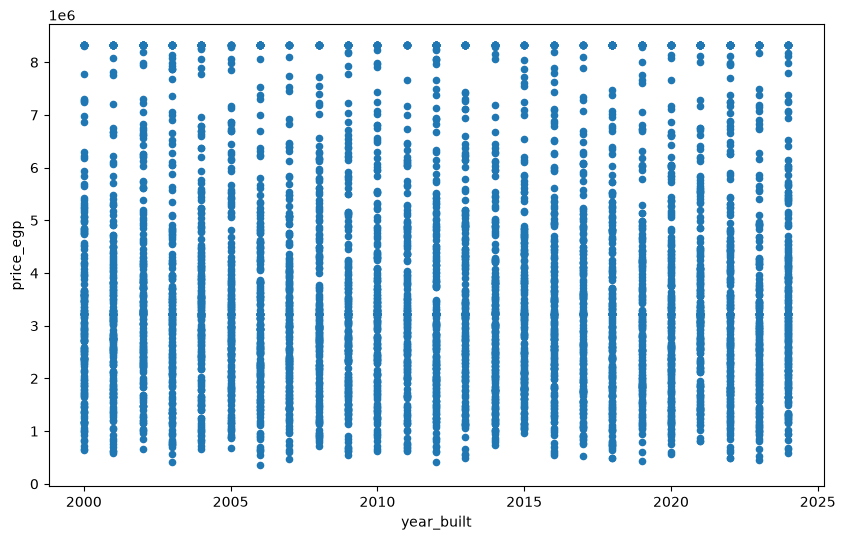

In [29]:
df.plot(kind='scatter',x='year_built',y='price_egp',figsize=(10,6))

##### 8-Price per sqm by Governorate

In [30]:
df['price_per_sqm'] = df['price_egp'] / df['area_sqm']

<Axes: xlabel='governorate_name'>

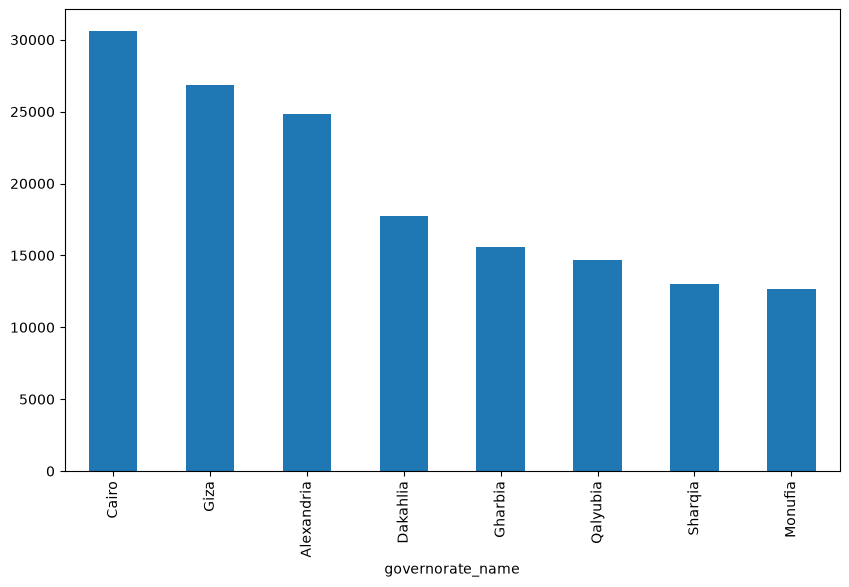

In [31]:
df.groupby('governorate_name')['price_per_sqm'].mean().sort_values(ascending=False).plot(kind='bar',figsize=(10,6))

##### 9-Top Areas by Average Price per sqm

<Axes: xlabel='city_region'>

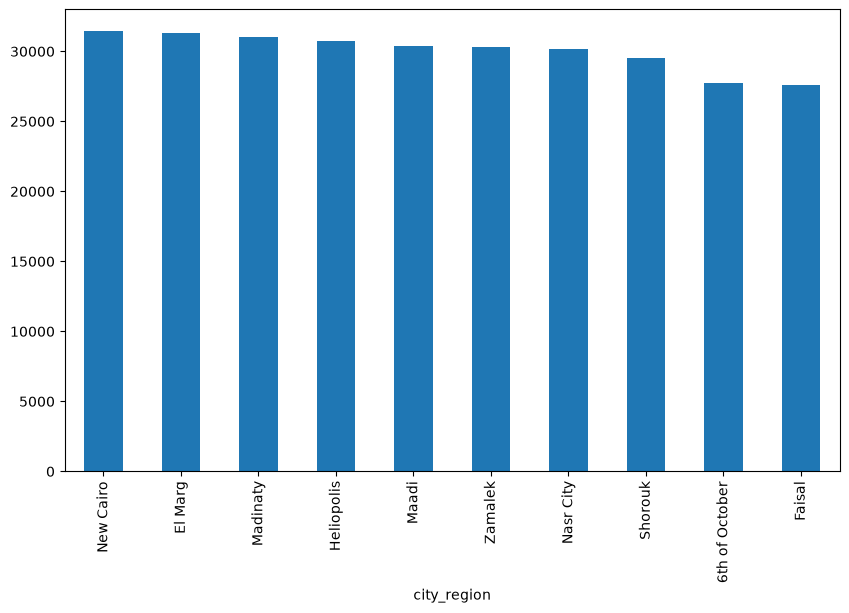

In [32]:
Top_areas = df.groupby('city_region')['price_per_sqm'].mean().sort_values(ascending=False).head(10)
Top_areas.plot(kind='bar', figsize=(10,6))

In [33]:
df.head(1)

,governorate_name,city_region,property_type,area_sqm,bedrooms_num,bathrooms_num,finishing_type,payment_method,year_built,price_egp,price_per_sqm
0,Giza,Dokki,Apartment,140.0,1.0,1,Finished,Cash,2000,4.457784e+06,31841.3137


##### 10-Correlation Heatmap

In [34]:
df.loc[:,['area_sqm','bedrooms_num','bathrooms_num','year_built','price_egp']].corr()*100

,area_sqm,bedrooms_num,bathrooms_num,year_built,price_egp
area_sqm,100.000000,-0.010097,-1.149736,0.779766,76.519988
bedrooms_num,-0.010097,100.000000,81.531652,0.221484,-0.960320
bathrooms_num,-1.149736,81.531652,100.000000,-0.034585,-1.430269
year_built,0.779766,0.221484,-0.034585,100.000000,-0.422308
price_egp,76.519988,-0.960320,-1.430269,-0.422308,100.000000


## Conclusion & Key Insights

This analysis explored 5,120 property listings in the Egyptian housing market and highlighted several key insights:

- **Location matters:** Cairo had the highest number of listings, followed by Giza and Alexandria.
- **Area affects price:** Larger properties generally tend to have higher prices, although other factors also influence price.
- **Property characteristics matter:** Prices vary by property type, finishing level, and number of bedrooms.
- **Price per sqm:** This metric provides a fairer comparison between properties and helped identify areas with the highest average prices per sqm.
- **Strong relationship:** Bedrooms and bathrooms showed a strong positive correlation.
- **Price correlations:** Area had a positive correlation with price , while year built had a negative correlation .

**Overall, property prices are influenced by multiple factors, especially location, size, and property characteristics, rather than a single factor.**

## Conclusion

This analysis provided an overview of property prices in Egypt and explored how prices vary based on location, property type, area, bedrooms, finishing level, and year built.

The analysis also examined price per square meter and the relationships between numerical variables, helping identify key factors associated with property prices.